⏳ Đang tải dữ liệu ETHUSDT khung 1h...

METRICS (KC Breakout + RSI + Pending STOP + Trailing)
Final Equity:      12898.5488
Total Return:      0.2899
CAGR (approx):     0.1368
Max Drawdown:      -0.1207
Sharpe:            0.9522
Trades:            354
Winrate:           0.4887
Avg PnL/Trade:     7.7424
Profit Factor:     1.1391


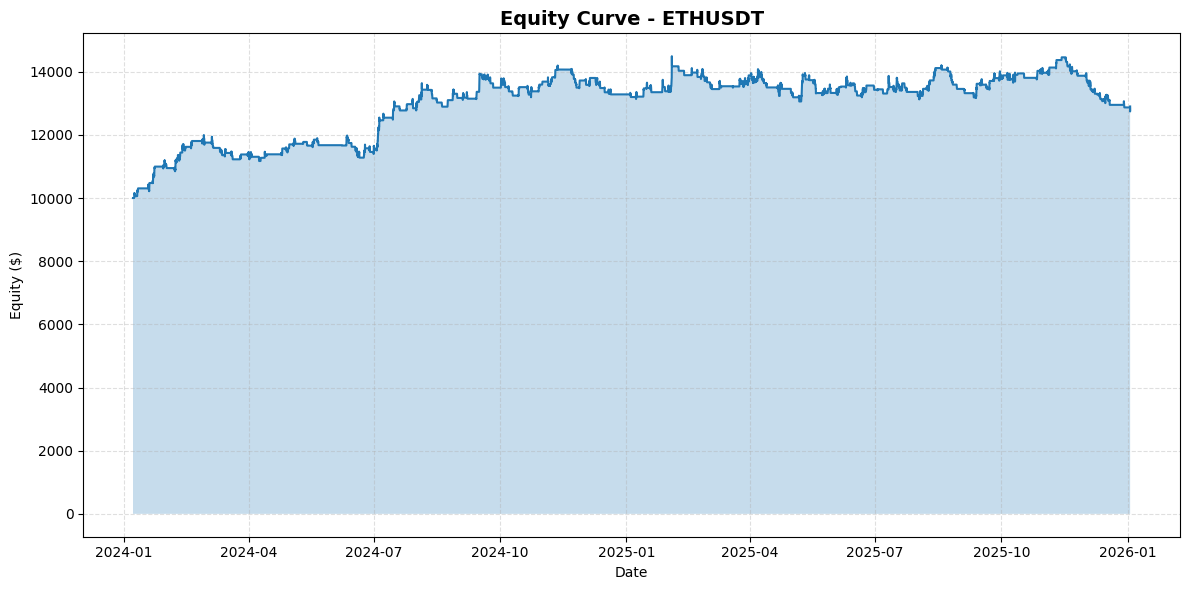


📊 Sample trades (first 10):
            Exit Time   Type          Entry Time        Entry         Exit       Qty           SL           TP   Gross PnL  Entry Fee  Exit Fee         PnL                Reason       Balance
0 2024-01-08 18:00:00   LONG 2024-01-08 17:00:00  2289.073701  2338.096273  3.271988  2258.511244  2338.096273  160.401280        0.0       0.0  160.401280           Take Profit  10160.401280
1 2024-01-09 12:00:00   LONG 2024-01-08 20:00:00  2354.570000  2276.346013  1.298886  2276.346013  2367.594804 -101.604013        0.0       0.0 -101.604013  Stop Loss / Trailing  10058.797267
2 2024-01-10 23:00:00   LONG 2024-01-10 21:00:00  2491.893647  2583.143665  1.716816  2533.317104  2583.143665  156.659524        0.0       0.0  156.659524           Take Profit  10215.456791
3 2024-01-11 11:00:00   LONG 2024-01-11 00:00:00  2584.370000  2665.376610  1.107306  2604.734603  2665.376610   89.699091        0.0       0.0   89.699091           Take Profit  10305.155882
4 2024-01-1

In [2]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1) BINANCE DATA
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200:
                print("Error:", r.status_code, r.text)
                break
            data = r.json()
            if not data:
                break
            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)
        except Exception as e:
            print("Lỗi:", e)
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp","Open","High","Low","Close","Volume",
        "close_time","quote_asset_volume","num_trades",
        "taker_buy_base_volume","taker_buy_quote_volume","ignore"
    ])
    df = df[["timestamp","Open","High","Low","Close","Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# =========================================================
# 2) INDICATORS
# - RSI(5) on Close
# - RSI(40) on Weighted Close
# - Keltner on Open: EMA(Open,20) +/- 2*ATR20
# - ATR: 20/25/40/170 (EWMA)
# - Highest/Lowest Close 20 shifted 3
# =========================================================
def rsi_wilder(series: pd.Series, period: int) -> pd.Series:
    delta = series.diff()
    gain = delta.clip(lower=0.0)
    loss = (-delta).clip(lower=0.0)

    avg_gain = gain.ewm(alpha=1/period, adjust=False, min_periods=period).mean()
    avg_loss = loss.ewm(alpha=1/period, adjust=False, min_periods=period).mean()

    rs = avg_gain / avg_loss.replace(0, np.nan)
    rsi = 100 - (100 / (1 + rs))
    return rsi

def atr_ewm(df: pd.DataFrame, period: int) -> pd.Series:
    prev_close = df["Close"].shift(1)
    tr = pd.concat([
        (df["High"] - df["Low"]),
        (df["High"] - prev_close).abs(),
        (df["Low"] - prev_close).abs()
    ], axis=1).max(axis=1)
    return tr.ewm(alpha=1/period, adjust=False, min_periods=period).mean()

def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    # Weighted close (typical for "weighted_close"): (H+L+2C)/4
    data["WClose"] = (data["High"] + data["Low"] + 2*data["Close"]) / 4.0

    # RSI
    data["RSI_5"] = rsi_wilder(data["Close"], 5)
    data["RSI_40_W"] = rsi_wilder(data["WClose"], 40)

    # ATRs
    data["ATR_20"] = atr_ewm(data, 20)
    data["ATR_25"] = atr_ewm(data, 25)
    data["ATR_40"] = atr_ewm(data, 40)
    data["ATR_170"] = atr_ewm(data, 170)

    # Keltner on OPEN, period 20, mult 2
    data["EMA_OPEN_20"] = data["Open"].ewm(span=20, adjust=False).mean()
    data["KC_Upper"] = data["EMA_OPEN_20"] + 2.0 * data["ATR_20"]
    data["KC_Lower"] = data["EMA_OPEN_20"] - 2.0 * data["ATR_20"]

    # Highest/Lowest Close lookback=20 shifted by 3 bars
    data["Highest_Close_20_shift3"] = data["Close"].rolling(20).max().shift(3)
    data["Lowest_Close_20_shift3"] = data["Close"].rolling(20).min().shift(3)

    # Shifted ATR references
    data["ATR40_shift3"] = data["ATR_40"].shift(3)
    data["ATR20_shift1"] = data["ATR_20"].shift(1)
    data["ATR25_shift1"] = data["ATR_25"].shift(1)
    data["ATR170_shift1"] = data["ATR_170"].shift(1)

    data.dropna(inplace=True)
    return data

# =========================================================
# 3) BACKTESTER (Pending STOP + SL/TP + Trailing + Expiry)
# =========================================================
class KCRSI_PendingStop_Backtester:
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        # Position state
        self.position = None  # None / 'LONG' / 'SHORT'
        self.entry_price = 0.0
        self.entry_time = None
        self.entry_bar_idx = -1
        self.qty = 0.0
        self.sl = 0.0
        self.tp = 0.0

        # Trailing
        self.trailing_active = False

        # Pending order (only 1 at a time per logic)
        # {'type': 'BUY_STOP'/'SELL_STOP', 'price':..., 'sl':..., 'tp':..., 'expire_idx':..., 'atr170':...}
        self.pending = None

        # Logs
        self.trades = []
        self.equity_curve = []

        # ---------------- Parameters (theo mô tả) ----------------
        self.lookback = 20

        self.price_entry_mult = 2.4      # PriceEntryMult
        self.stoploss_coef = 1.7         # StopLossCoef
        self.profit_target_coef = 2.8    # ProfitTargetCoef

        self.pending_expiration_bars = 6

        # Trailing
        self.trailing_stop_coef = 2.3    # TrailingStopCoef
        self.trailing_activation_points = 80.0  # TrailingActivation (đơn vị giá)

        # Money management
        self.use_mm = True
        self.mm_risk_pct = 0.01          # 1% balance
        self.mm_max_lots = 100.0         # cap qty (coin units) để tránh lỗi (tuỳ bạn)
        self.mm_lots_if_no_mm = 1.0

        # Costs (optional)
        self.fee_rate = 0.0            # set 0.0004 nếu muốn
        self.slippage_bps = 0.0        # set 2.0 nếu muốn (2 bps)

    # ---------------- helper ----------------
    def _apply_slippage(self, side: str, price: float) -> float:
        if self.slippage_bps <= 0:
            return price
        m = 1.0 + self.slippage_bps / 10000.0
        if side == "buy":
            return price * m
        return price / m  # sell

    def _pay_fee(self, notional: float):
        if self.fee_rate <= 0:
            return 0.0
        fee = abs(notional) * self.fee_rate
        self.balance -= fee
        return fee

    def _equity(self, close_price: float) -> float:
        eq = self.balance
        if self.position == "LONG":
            eq += (close_price - self.entry_price) * self.qty
        elif self.position == "SHORT":
            eq += (self.entry_price - close_price) * self.qty
        return eq

    def _calc_qty(self, entry_price: float, sl_price: float) -> float:
        if not self.use_mm:
            return float(self.mm_lots_if_no_mm)

        risk_amt = self.balance * self.mm_risk_pct
        sl_dist = abs(entry_price - sl_price)
        if sl_dist <= 0:
            return 0.0
        qty = risk_amt / sl_dist

        # cap qty
        qty = min(qty, self.mm_max_lots)
        return max(qty, 0.0)

    # ---------------- order/position actions ----------------
    def _open_position(self, side: str, fill_price: float, i: int, time_idx, sl_price: float, tp_price: float):
        # Apply slippage
        if side == "LONG":
            fill = self._apply_slippage("buy", fill_price)
        else:
            fill = self._apply_slippage("sell", fill_price)

        qty = self._calc_qty(fill, sl_price)
        if qty <= 0:
            return

        # Pay entry fee
        entry_fee = self._pay_fee(qty * fill)

        self.position = side
        self.entry_price = fill
        self.entry_time = time_idx
        self.entry_bar_idx = i
        self.qty = qty
        self.sl = sl_price
        self.tp = tp_price
        self.trailing_active = False

        # store entry fee for logging
        self._last_entry_fee = entry_fee

    def _close_position(self, exit_price: float, time_idx, reason: str):
        if self.position is None or self.qty <= 0:
            return

        # Apply slippage
        if self.position == "LONG":
            px = self._apply_slippage("sell", exit_price)
            gross_pnl = (px - self.entry_price) * self.qty
        else:
            px = self._apply_slippage("buy", exit_price)
            gross_pnl = (self.entry_price - px) * self.qty

        # Pay exit fee
        exit_fee = self._pay_fee(self.qty * px)

        self.balance += gross_pnl
        net_pnl = gross_pnl - getattr(self, "_last_entry_fee", 0.0) - exit_fee

        self.trades.append({
            "Exit Time": time_idx,
            "Type": self.position,
            "Entry Time": self.entry_time,
            "Entry": self.entry_price,
            "Exit": px,
            "Qty": self.qty,
            "SL": self.sl,
            "TP": self.tp,
            "Gross PnL": gross_pnl,
            "Entry Fee": getattr(self, "_last_entry_fee", 0.0),
            "Exit Fee": exit_fee,
            "PnL": net_pnl,
            "Reason": reason,
            "Balance": self.balance
        })

        # reset
        self.position = None
        self.entry_price = 0.0
        self.entry_time = None
        self.entry_bar_idx = -1
        self.qty = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.trailing_active = False
        self._last_entry_fee = 0.0

    def _place_or_replace_pending(self, ptype: str, price: float, sl_price: float, tp_price: float, expire_idx: int, atr170: float):
        # replace existing same-direction pending (as described)
        self.pending = {
            "type": ptype,
            "price": float(price),
            "sl": float(sl_price),
            "tp": float(tp_price),
            "expire_idx": int(expire_idx),
            "atr170": float(atr170),
        }

    # ---------------- main loop ----------------
    def run(self):
        idxs = self.df.index

        for i in range(len(self.df)):
            bar = self.df.iloc[i]
            t = idxs[i]

            O = float(bar["Open"])
            H = float(bar["High"])
            L = float(bar["Low"])
            C = float(bar["Close"])

            # ========== 1) Manage open position ==========
            if self.position is not None:
                # Trailing activation check (profit >= activation points)
                if not self.trailing_active:
                    if self.position == "LONG":
                        if (H - self.entry_price) >= self.trailing_activation_points:
                            self.trailing_active = True
                    else:
                        if (self.entry_price - L) >= self.trailing_activation_points:
                            self.trailing_active = True

                # Update trailing SL if active
                if self.trailing_active:
                    trail_dist = self.trailing_stop_coef * float(bar["ATR170_shift1"])
                    if self.position == "LONG":
                        new_sl = (C - trail_dist)
                        if new_sl > self.sl:
                            self.sl = new_sl
                    else:
                        new_sl = (C + trail_dist)
                        if new_sl < self.sl:
                            self.sl = new_sl

                # Exit checks (no reverse signal exits)
                if self.position == "LONG":
                    if L <= self.sl:
                        self._close_position(self.sl, t, "Stop Loss / Trailing")
                    elif H >= self.tp:
                        self._close_position(self.tp, t, "Take Profit")
                else:
                    if H >= self.sl:
                        self._close_position(self.sl, t, "Stop Loss / Trailing")
                    elif L <= self.tp:
                        self._close_position(self.tp, t, "Take Profit")

            # ========== 2) Manage pending order ==========
            if self.position is None and self.pending is not None:
                # Expire
                if i >= self.pending["expire_idx"]:
                    self.pending = None
                else:
                    p = float(self.pending["price"])
                    if self.pending["type"] == "BUY_STOP":
                        if H >= p:
                            fill = max(p, O)  # gap-aware
                            self._open_position(
                                "LONG", fill, i, t,
                                sl_price=float(self.pending["sl"]),
                                tp_price=float(self.pending["tp"])
                            )
                            self.pending = None
                    else:  # SELL_STOP
                        if L <= p:
                            fill = min(p, O)
                            self._open_position(
                                "SHORT", fill, i, t,
                                sl_price=float(self.pending["sl"]),
                                tp_price=float(self.pending["tp"])
                            )
                            self.pending = None

            # ========== 3) Create signals & place pending ==========
            if self.position is None:
                # Need shifts up to 3
                if i < 3:
                    self.equity_curve.append({"time": t, "equity": self._equity(C)})
                    continue

                # LongEntrySignal conditions:
                # RSI5 shift3 < shift2  (rising)
                # Open(0) > KC_upper
                # RSI40(WClose) shift3 < shift2 (rising)
                rsi5_s3 = float(self.df.iloc[i-3]["RSI_5"])
                rsi5_s2 = float(self.df.iloc[i-2]["RSI_5"])
                rsi40_s3 = float(self.df.iloc[i-3]["RSI_40_W"])
                rsi40_s2 = float(self.df.iloc[i-2]["RSI_40_W"])
                kc_up = float(bar["KC_Upper"])
                kc_lo = float(bar["KC_Lower"])

                long_signal = (rsi5_s3 < rsi5_s2) and (O > kc_up) and (rsi40_s3 < rsi40_s2)
                short_signal = (rsi5_s3 > rsi5_s2) and (O < kc_lo) and (rsi40_s3 > rsi40_s2)

                # If signal -> place pending stop
                if long_signal:
                    entry = float(bar["Highest_Close_20_shift3"]) + self.price_entry_mult * float(bar["ATR40_shift3"])
                    sl_dist = self.stoploss_coef * float(bar["ATR20_shift1"])
                    tp_dist = self.profit_target_coef * float(bar["ATR25_shift1"])

                    sl = entry - sl_dist
                    tp = entry + tp_dist

                    self._place_or_replace_pending(
                        "BUY_STOP", entry, sl, tp,
                        expire_idx=i + self.pending_expiration_bars,
                        atr170=float(bar["ATR170_shift1"])
                    )

                elif short_signal and (not long_signal):
                    entry = float(bar["Lowest_Close_20_shift3"]) - self.price_entry_mult * float(bar["ATR40_shift3"])
                    sl_dist = self.stoploss_coef * float(bar["ATR20_shift1"])
                    tp_dist = self.profit_target_coef * float(bar["ATR25_shift1"])

                    sl = entry + sl_dist
                    tp = entry - tp_dist

                    self._place_or_replace_pending(
                        "SELL_STOP", entry, sl, tp,
                        expire_idx=i + self.pending_expiration_bars,
                        atr170=float(bar["ATR170_shift1"])
                    )

            # ========== 4) Append equity ==========
            self.equity_curve.append({"time": t, "equity": self._equity(C)})

# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data).copy()
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = float(eq_df["equity"].iloc[-1])
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    dd = (eq_df["equity"] - running_max) / running_max
    max_dd = float(dd.min())

    eq_df["ret"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["ret"].mean()
    std_ret = eq_df["ret"].std()
    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret and std_ret != 0 else 0.0

    total_trades = len(trades_df)
    win_trades = int((trades_df["PnL"] > 0).sum()) if total_trades > 0 else 0
    win_rate = (win_trades / total_trades) if total_trades > 0 else 0.0
    avg_pnl = trades_df["PnL"].mean() if total_trades > 0 else 0.0

    gross_profit = trades_df.loc[trades_df["PnL"] > 0, "PnL"].sum() if total_trades > 0 else 0.0
    gross_loss = abs(trades_df.loc[trades_df["PnL"] < 0, "PnL"].sum()) if total_trades > 0 else 0.0
    profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*70)
    print("METRICS (KC Breakout + RSI + Pending STOP + Trailing)")
    print("="*70)
    print(f"Final Equity:      {metrics['Final Equity']:.4f}")
    print(f"Total Return:      {metrics['Total Return']:.4f}")
    print(f"CAGR (approx):     {metrics['CAGR']:.4f}")
    print(f"Max Drawdown:      {metrics['Max Drawdown']:.4f}")
    print(f"Sharpe:            {metrics['Sharpe']:.4f}")
    print(f"Trades:            {metrics['Trades']}")
    print(f"Winrate:           {metrics['Winrate']:.4f}")
    print(f"Avg PnL/Trade:     {metrics['Avg PnL/Trade']:.4f}")
    print(f"Profit Factor:     {metrics['Profit Factor']:.4f}")
    print("="*70)

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.25)
    plt.title(f"Equity Curve - {symbol}", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "02/01/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)
    if len(df_raw) < 500:
        print("❌ Không đủ dữ liệu.")
        raise SystemExit

    df_calc = calculate_indicators(df_raw)

    bt = KCRSI_PendingStop_Backtester(df_calc, initial_balance=10000.0)

    # ==== Tune parameters if needed ====
    bt.price_entry_mult = 2.4
    bt.stoploss_coef = 1.7
    bt.profit_target_coef = 2.8

    bt.trailing_stop_coef = 2.3
    bt.trailing_activation_points = 80.0  # ETH: 80$, BTC: 80$ là rất nhỏ -> thường tăng lên 200~800

    bt.pending_expiration_bars = 6

    bt.mm_risk_pct = 0.01
    bt.mm_max_lots = 100.0

    # Costs (optional realism)
    bt.fee_rate = 0.0
    bt.slippage_bps = 0.0
    # ================================

    bt.run()

    trades_df = pd.DataFrame(bt.trades)
    if trades_df.empty:
        print("⚠️ Không có lệnh nào.")
        raise SystemExit

    metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
    print_report_and_plot(metrics, symbol)

    print("\n📊 Sample trades (first 10):")
    print(trades_df.head(10).to_string())

    print("\n📊 Exit reason distribution:")
    print(trades_df["Reason"].value_counts())

⏳ Đang tải dữ liệu ETHUSDT khung 1h...

METRICS (KC+RSI Pending STOP + Trailing ALWAYS ON)
Final Equity:      10770.6909
Total Return:      0.0771
CAGR (approx):     0.0677
Max Drawdown:      -0.1448
Sharpe:            0.5346
Trades:            215
Winrate:           0.4372
Avg PnL/Trade:     3.5846
Profit Factor:     1.0904


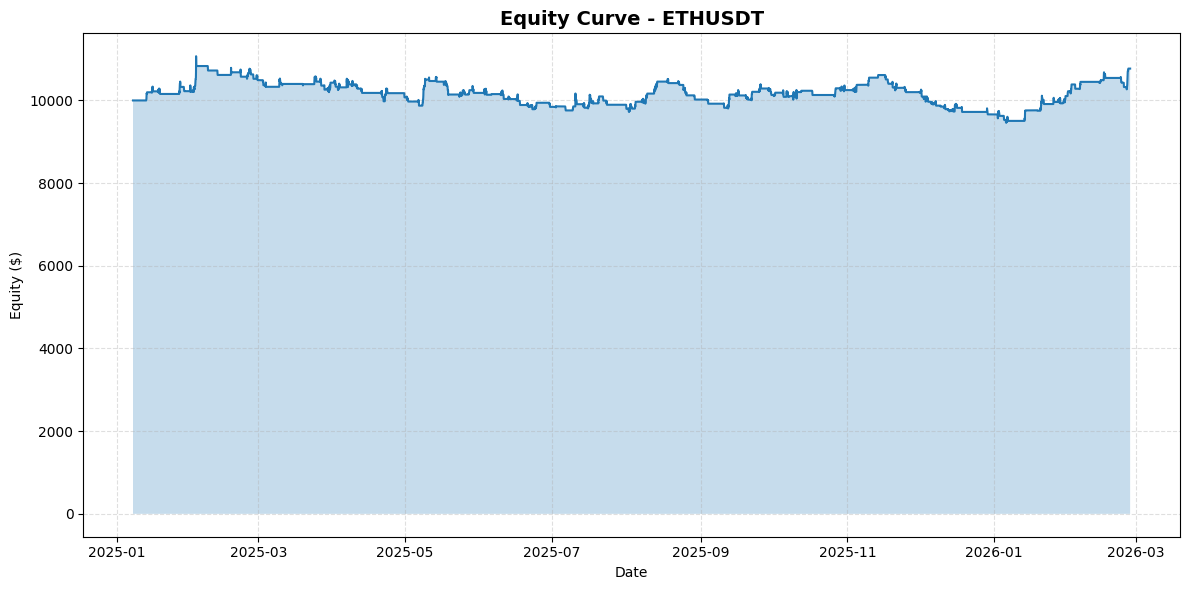


📊 Sample trades (first 10):
            Exit Time   Type          Entry Time        Entry         Exit       Qty           SL           TP   Gross PnL  Entry Fee  Exit Fee         PnL                Reason       Balance
0 2025-01-13 11:00:00  SHORT 2025-01-13 08:00:00  3175.889638  3102.026510  2.191257  3143.318394  3102.026510  161.853090        0.0       0.0  161.853090           Take Profit  10161.853090
1 2025-01-13 14:00:00  SHORT 2025-01-13 12:00:00  3057.150000  3022.827511  1.038414  3121.366826  3022.827511   35.640941        0.0       0.0   35.640941           Take Profit  10197.494031
2 2025-01-15 19:00:00   LONG 2025-01-15 15:00:00  3329.490000  3407.334656  1.463115  3349.461661  3407.334656  113.895668        0.0       0.0  113.895668           Take Profit  10311.389699
3 2025-01-16 03:00:00   LONG 2025-01-15 21:00:00  3434.040000  3365.918218  1.338415  3365.918218  3519.212142  -91.175191        0.0       0.0  -91.175191  Stop Loss / Trailing  10220.214508
4 2025-01-1

In [4]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1) BINANCE DATA
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        r = requests.get(url, params=params, timeout=10)
        if r.status_code != 200:
            print("Error:", r.status_code, r.text)
            break
        data = r.json()
        if not data:
            break
        all_klines.extend(data)
        start_time = data[-1][0] + 1
        time.sleep(0.05)

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp","Open","High","Low","Close","Volume",
        "close_time","quote_asset_volume","num_trades",
        "taker_buy_base_volume","taker_buy_quote_volume","ignore"
    ])
    df = df[["timestamp","Open","High","Low","Close","Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# =========================================================
# 2) INDICATORS
# =========================================================
def rsi_wilder(series: pd.Series, period: int) -> pd.Series:
    delta = series.diff()
    gain = delta.clip(lower=0.0)
    loss = (-delta).clip(lower=0.0)

    avg_gain = gain.ewm(alpha=1/period, adjust=False, min_periods=period).mean()
    avg_loss = loss.ewm(alpha=1/period, adjust=False, min_periods=period).mean()

    rs = avg_gain / avg_loss.replace(0, np.nan)
    return 100 - (100 / (1 + rs))

def atr_ewm(df: pd.DataFrame, period: int) -> pd.Series:
    prev_close = df["Close"].shift(1)
    tr = pd.concat([
        (df["High"] - df["Low"]),
        (df["High"] - prev_close).abs(),
        (df["Low"] - prev_close).abs()
    ], axis=1).max(axis=1)
    return tr.ewm(alpha=1/period, adjust=False, min_periods=period).mean()

def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    data["WClose"] = (data["High"] + data["Low"] + 2*data["Close"]) / 4.0

    data["RSI_5"] = rsi_wilder(data["Close"], 5)
    data["RSI_40_W"] = rsi_wilder(data["WClose"], 40)

    data["ATR_20"] = atr_ewm(data, 20)
    data["ATR_25"] = atr_ewm(data, 25)
    data["ATR_40"] = atr_ewm(data, 40)
    data["ATR_170"] = atr_ewm(data, 170)

    data["EMA_OPEN_20"] = data["Open"].ewm(span=20, adjust=False).mean()
    data["KC_Upper"] = data["EMA_OPEN_20"] + 2.0 * data["ATR_20"]
    data["KC_Lower"] = data["EMA_OPEN_20"] - 2.0 * data["ATR_20"]

    data["Highest_Close_20_shift3"] = data["Close"].rolling(20).max().shift(3)
    data["Lowest_Close_20_shift3"] = data["Close"].rolling(20).min().shift(3)

    data["ATR40_shift3"] = data["ATR_40"].shift(3)
    data["ATR20_shift1"] = data["ATR_20"].shift(1)
    data["ATR25_shift1"] = data["ATR_25"].shift(1)
    data["ATR170_shift1"] = data["ATR_170"].shift(1)

    data.dropna(inplace=True)
    return data

# =========================================================
# 3) BACKTESTER (Trailing ALWAYS ON)
# =========================================================
class KCRSI_PendingStop_Backtester_NoActivation:
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.position = None  # None/'LONG'/'SHORT'
        self.entry_price = 0.0
        self.entry_time = None
        self.entry_bar_idx = -1
        self.qty = 0.0
        self.sl = 0.0
        self.tp = 0.0

        # Pending
        self.pending = None  # {'type','price','sl','tp','expire_idx'}

        self.trades = []
        self.equity_curve = []

        # Params
        self.lookback = 20
        self.price_entry_mult = 2.4
        self.stoploss_coef = 1.7
        self.profit_target_coef = 2.8

        self.pending_expiration_bars = 6

        # Trailing (always on)
        self.trailing_stop_coef = 2.3  # * ATR170_shift1

        # Money management
        self.use_mm = True
        self.mm_risk_pct = 0.01
        self.mm_max_lots = 100.0
        self.mm_lots_if_no_mm = 1.0

        # Costs (optional)
        self.fee_rate = 0.0
        self.slippage_bps = 0.0

        self._last_entry_fee = 0.0

    def _apply_slippage(self, side: str, price: float) -> float:
        if self.slippage_bps <= 0:
            return price
        m = 1.0 + self.slippage_bps / 10000.0
        return price * m if side == "buy" else price / m

    def _pay_fee(self, notional: float) -> float:
        if self.fee_rate <= 0:
            return 0.0
        fee = abs(notional) * self.fee_rate
        self.balance -= fee
        return fee

    def _equity(self, close_price: float) -> float:
        eq = self.balance
        if self.position == "LONG":
            eq += (close_price - self.entry_price) * self.qty
        elif self.position == "SHORT":
            eq += (self.entry_price - close_price) * self.qty
        return eq

    def _calc_qty(self, entry_price: float, sl_price: float) -> float:
        if not self.use_mm:
            return float(self.mm_lots_if_no_mm)

        risk_amt = self.balance * self.mm_risk_pct
        sl_dist = abs(entry_price - sl_price)
        if sl_dist <= 0:
            return 0.0
        qty = risk_amt / sl_dist
        qty = min(qty, self.mm_max_lots)
        return max(qty, 0.0)

    def _open_position(self, side: str, fill_price: float, i: int, time_idx, sl_price: float, tp_price: float):
        fill = self._apply_slippage("buy" if side == "LONG" else "sell", fill_price)

        qty = self._calc_qty(fill, sl_price)
        if qty <= 0:
            return

        self._last_entry_fee = self._pay_fee(qty * fill)

        self.position = side
        self.entry_price = fill
        self.entry_time = time_idx
        self.entry_bar_idx = i
        self.qty = qty
        self.sl = sl_price
        self.tp = tp_price

    def _close_position(self, exit_price: float, time_idx, reason: str):
        if self.position is None or self.qty <= 0:
            return

        px = self._apply_slippage("sell" if self.position == "LONG" else "buy", exit_price)

        if self.position == "LONG":
            gross_pnl = (px - self.entry_price) * self.qty
        else:
            gross_pnl = (self.entry_price - px) * self.qty

        exit_fee = self._pay_fee(self.qty * px)

        self.balance += gross_pnl
        net_pnl = gross_pnl - self._last_entry_fee - exit_fee

        self.trades.append({
            "Exit Time": time_idx,
            "Type": self.position,
            "Entry Time": self.entry_time,
            "Entry": self.entry_price,
            "Exit": px,
            "Qty": self.qty,
            "SL": self.sl,
            "TP": self.tp,
            "Gross PnL": gross_pnl,
            "Entry Fee": self._last_entry_fee,
            "Exit Fee": exit_fee,
            "PnL": net_pnl,
            "Reason": reason,
            "Balance": self.balance
        })

        # reset
        self.position = None
        self.entry_price = 0.0
        self.entry_time = None
        self.entry_bar_idx = -1
        self.qty = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self._last_entry_fee = 0.0

    def _place_pending(self, ptype: str, price: float, sl: float, tp: float, expire_idx: int):
        self.pending = {
            "type": ptype,
            "price": float(price),
            "sl": float(sl),
            "tp": float(tp),
            "expire_idx": int(expire_idx),
        }

    def run(self):
        idxs = self.df.index

        for i in range(len(self.df)):
            bar = self.df.iloc[i]
            t = idxs[i]

            O = float(bar["Open"])
            H = float(bar["High"])
            L = float(bar["Low"])
            C = float(bar["Close"])

            # 1) Manage open position (Trailing ALWAYS updates)
            if self.position is not None:
                trail_dist = self.trailing_stop_coef * float(bar["ATR170_shift1"])

                if self.position == "LONG":
                    # update trailing SL upward
                    new_sl = C - trail_dist
                    if new_sl > self.sl:
                        self.sl = new_sl

                    # exit checks
                    if L <= self.sl:
                        self._close_position(self.sl, t, "Stop Loss / Trailing")
                    elif H >= self.tp:
                        self._close_position(self.tp, t, "Take Profit")

                else:  # SHORT
                    new_sl = C + trail_dist
                    if new_sl < self.sl:
                        self.sl = new_sl

                    if H >= self.sl:
                        self._close_position(self.sl, t, "Stop Loss / Trailing")
                    elif L <= self.tp:
                        self._close_position(self.tp, t, "Take Profit")

            # 2) Manage pending
            if self.position is None and self.pending is not None:
                if i >= self.pending["expire_idx"]:
                    self.pending = None
                else:
                    p = float(self.pending["price"])
                    if self.pending["type"] == "BUY_STOP" and H >= p:
                        fill = max(p, O)
                        self._open_position("LONG", fill, i, t, self.pending["sl"], self.pending["tp"])
                        self.pending = None
                    elif self.pending["type"] == "SELL_STOP" and L <= p:
                        fill = min(p, O)
                        self._open_position("SHORT", fill, i, t, self.pending["sl"], self.pending["tp"])
                        self.pending = None

            # 3) Create signals & place pending
            if self.position is None:
                if i < 3:
                    self.equity_curve.append({"time": t, "equity": self._equity(C)})
                    continue

                rsi5_s3 = float(self.df.iloc[i-3]["RSI_5"])
                rsi5_s2 = float(self.df.iloc[i-2]["RSI_5"])
                rsi40_s3 = float(self.df.iloc[i-3]["RSI_40_W"])
                rsi40_s2 = float(self.df.iloc[i-2]["RSI_40_W"])

                kc_up = float(bar["KC_Upper"])
                kc_lo = float(bar["KC_Lower"])

                long_signal = (rsi5_s3 < rsi5_s2) and (O > kc_up) and (rsi40_s3 < rsi40_s2)
                short_signal = (rsi5_s3 > rsi5_s2) and (O < kc_lo) and (rsi40_s3 > rsi40_s2)

                if long_signal:
                    entry = float(bar["Highest_Close_20_shift3"]) + self.price_entry_mult * float(bar["ATR40_shift3"])
                    sl_dist = self.stoploss_coef * float(bar["ATR20_shift1"])
                    tp_dist = self.profit_target_coef * float(bar["ATR25_shift1"])
                    sl = entry - sl_dist
                    tp = entry + tp_dist
                    self._place_pending("BUY_STOP", entry, sl, tp, i + self.pending_expiration_bars)

                elif short_signal and (not long_signal):
                    entry = float(bar["Lowest_Close_20_shift3"]) - self.price_entry_mult * float(bar["ATR40_shift3"])
                    sl_dist = self.stoploss_coef * float(bar["ATR20_shift1"])
                    tp_dist = self.profit_target_coef * float(bar["ATR25_shift1"])
                    sl = entry + sl_dist
                    tp = entry - tp_dist
                    self._place_pending("SELL_STOP", entry, sl, tp, i + self.pending_expiration_bars)

            # 4) Equity
            self.equity_curve.append({"time": t, "equity": self._equity(C)})

# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data).copy()
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = float(eq_df["equity"].iloc[-1])
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    dd = (eq_df["equity"] - running_max) / running_max
    max_dd = float(dd.min())

    eq_df["ret"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["ret"].mean()
    std_ret = eq_df["ret"].std()
    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret and std_ret != 0 else 0.0

    total_trades = len(trades_df)
    win_trades = int((trades_df["PnL"] > 0).sum()) if total_trades > 0 else 0
    win_rate = (win_trades / total_trades) if total_trades > 0 else 0.0
    avg_pnl = trades_df["PnL"].mean() if total_trades > 0 else 0.0

    gross_profit = trades_df.loc[trades_df["PnL"] > 0, "PnL"].sum() if total_trades > 0 else 0.0
    gross_loss = abs(trades_df.loc[trades_df["PnL"] < 0, "PnL"].sum()) if total_trades > 0 else 0.0
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*70)
    print("METRICS (KC+RSI Pending STOP + Trailing ALWAYS ON)")
    print("="*70)
    print(f"Final Equity:      {metrics['Final Equity']:.4f}")
    print(f"Total Return:      {metrics['Total Return']:.4f}")
    print(f"CAGR (approx):     {metrics['CAGR']:.4f}")
    print(f"Max Drawdown:      {metrics['Max Drawdown']:.4f}")
    print(f"Sharpe:            {metrics['Sharpe']:.4f}")
    print(f"Trades:            {metrics['Trades']}")
    print(f"Winrate:           {metrics['Winrate']:.4f}")
    print(f"Avg PnL/Trade:     {metrics['Avg PnL/Trade']:.4f}")
    print(f"Profit Factor:     {metrics['Profit Factor']:.4f}")
    print("="*70)

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.25)
    plt.title(f"Equity Curve - {symbol}", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2025"
    end_date = "26/02/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)
    if len(df_raw) < 500:
        print("❌ Không đủ dữ liệu.")
        raise SystemExit

    df_calc = calculate_indicators(df_raw)

    bt = KCRSI_PendingStop_Backtester_NoActivation(df_calc, initial_balance=10000.0)

    # Params
    bt.price_entry_mult = 2.4
    bt.stoploss_coef = 1.7
    bt.profit_target_coef = 2.8
    bt.trailing_stop_coef = 2.3

    bt.pending_expiration_bars = 6
    bt.mm_risk_pct = 0.01
    bt.mm_max_lots = 100.0

    # costs optional
    bt.fee_rate = 0.0
    bt.slippage_bps = 0.0

    bt.run()

    trades_df = pd.DataFrame(bt.trades)
    if trades_df.empty:
        print("⚠️ Không có lệnh nào.")
        raise SystemExit

    metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
    print_report_and_plot(metrics, symbol)

    print("\n📊 Sample trades (first 10):")
    print(trades_df.head(10).to_string())

    print("\n📊 Exit reason distribution:")
    print(trades_df["Reason"].value_counts())

⏳ Đang tải dữ liệu ETHUSDT khung 1h...

METRICS (KC+RSI Pending STOP + Trailing ALWAYS ON + ADX + CloseConfirm)
Final Equity:      10668.9594
Total Return:      0.0669
CAGR (approx):     0.0332
Max Drawdown:      -0.1382
Sharpe:            0.3168
Trades:            318
Winrate:           0.4434
Avg PnL/Trade:     1.6934
Profit Factor:     1.0381


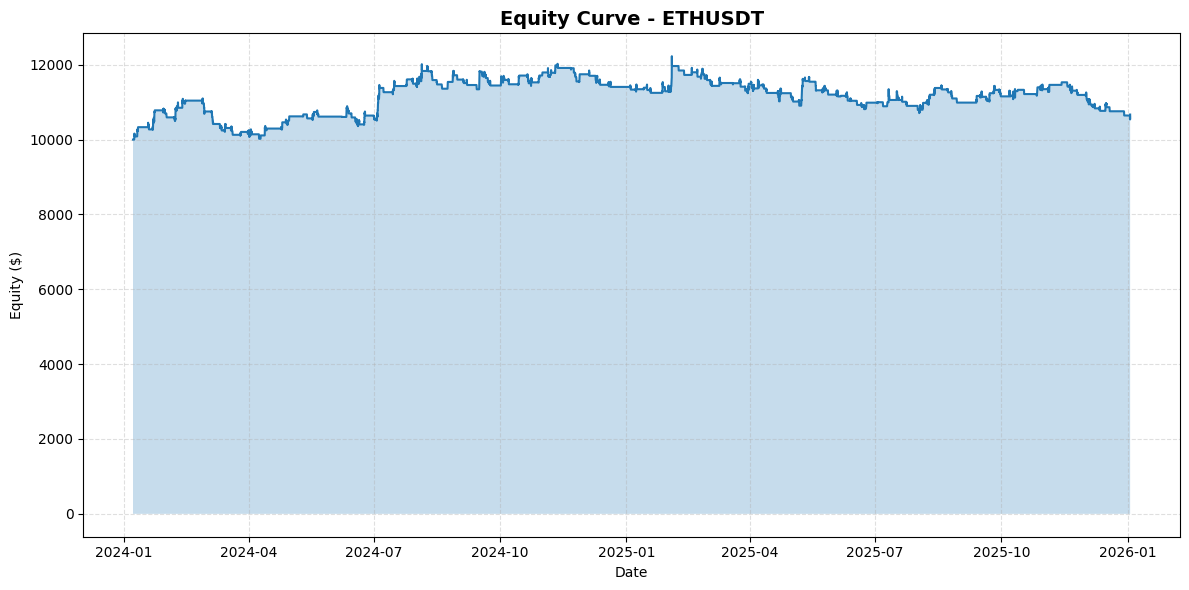


📊 Sample trades (first 10):
            Exit Time   Type          Entry Time        Entry         Exit       Qty           SL           TP   Gross PnL  Entry Fee  Exit Fee         PnL                Reason       Balance
0 2024-01-08 18:00:00   LONG 2024-01-08 17:00:00  2289.073701  2338.096273  3.271988  2295.332587  2338.096273  160.401280        0.0       0.0  160.401280           Take Profit  10160.401280
1 2024-01-09 00:00:00   LONG 2024-01-08 20:00:00  2354.570000  2296.473075  1.298886  2296.473075  2367.594804  -75.461261        0.0       0.0  -75.461261  Stop Loss / Trailing  10084.940019
2 2024-01-10 23:00:00   LONG 2024-01-10 21:00:00  2491.893647  2583.143665  1.721278  2533.317104  2583.143665  157.066681        0.0       0.0  157.066681           Take Profit  10242.006700
3 2024-01-11 11:00:00   LONG 2024-01-11 00:00:00  2584.370000  2665.376610  1.110184  2604.734603  2665.376610   89.932218        0.0       0.0   89.932218           Take Profit  10331.938918
4 2024-01-1

In [5]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1) BINANCE DATA
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200:
                print("Error:", r.status_code, r.text)
                break
            data = r.json()
            if not data:
                break
            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)
        except Exception as e:
            print("Lỗi:", e)
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp","Open","High","Low","Close","Volume",
        "close_time","quote_asset_volume","num_trades",
        "taker_buy_base_volume","taker_buy_quote_volume","ignore"
    ])
    df = df[["timestamp","Open","High","Low","Close","Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# =========================================================
# 2) INDICATORS (RSI + ATR + KC(Open) + Highest/Lowest + ADX)
# =========================================================
def rsi_wilder(series: pd.Series, period: int) -> pd.Series:
    delta = series.diff()
    gain = delta.clip(lower=0.0)
    loss = (-delta).clip(lower=0.0)

    avg_gain = gain.ewm(alpha=1/period, adjust=False, min_periods=period).mean()
    avg_loss = loss.ewm(alpha=1/period, adjust=False, min_periods=period).mean()

    rs = avg_gain / avg_loss.replace(0, np.nan)
    return 100 - (100 / (1 + rs))

def atr_ewm(df: pd.DataFrame, period: int) -> pd.Series:
    prev_close = df["Close"].shift(1)
    tr = pd.concat([
        (df["High"] - df["Low"]),
        (df["High"] - prev_close).abs(),
        (df["Low"] - prev_close).abs()
    ], axis=1).max(axis=1)
    return tr.ewm(alpha=1/period, adjust=False, min_periods=period).mean()

def adx_wilder(df: pd.DataFrame, n: int = 14) -> pd.Series:
    high, low, close = df["High"], df["Low"], df["Close"]

    up_move = high.diff()
    down_move = -low.diff()

    plus_dm = np.where((up_move > down_move) & (up_move > 0), up_move, 0.0)
    minus_dm = np.where((down_move > up_move) & (down_move > 0), down_move, 0.0)

    tr = pd.concat([
        (high - low),
        (high - close.shift(1)).abs(),
        (low - close.shift(1)).abs()
    ], axis=1).max(axis=1)

    atr = tr.ewm(alpha=1/n, adjust=False, min_periods=n).mean()
    plus_di = 100 * pd.Series(plus_dm, index=df.index).ewm(alpha=1/n, adjust=False, min_periods=n).mean() / atr
    minus_di = 100 * pd.Series(minus_dm, index=df.index).ewm(alpha=1/n, adjust=False, min_periods=n).mean() / atr

    dx = (100 * (plus_di - minus_di).abs() / (plus_di + minus_di)).replace([np.inf, -np.inf], np.nan)
    return dx.ewm(alpha=1/n, adjust=False, min_periods=n).mean()

def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    # Weighted Close ~ (H+L+2C)/4
    data["WClose"] = (data["High"] + data["Low"] + 2*data["Close"]) / 4.0

    # RSI
    data["RSI_5"] = rsi_wilder(data["Close"], 5)
    data["RSI_40_W"] = rsi_wilder(data["WClose"], 40)

    # ATRs
    data["ATR_20"] = atr_ewm(data, 20)
    data["ATR_25"] = atr_ewm(data, 25)
    data["ATR_40"] = atr_ewm(data, 40)
    data["ATR_170"] = atr_ewm(data, 170)

    # ADX(14) regime filter
    data["ADX_14"] = adx_wilder(data, 14)

    # Keltner on OPEN: EMA(Open,20) +/- 2*ATR20
    data["EMA_OPEN_20"] = data["Open"].ewm(span=20, adjust=False).mean()
    data["KC_Upper"] = data["EMA_OPEN_20"] + 2.0 * data["ATR_20"]
    data["KC_Lower"] = data["EMA_OPEN_20"] - 2.0 * data["ATR_20"]

    # Highest/Lowest Close lookback=20 shifted by 3 bars
    data["Highest_Close_20_shift3"] = data["Close"].rolling(20).max().shift(3)
    data["Lowest_Close_20_shift3"] = data["Close"].rolling(20).min().shift(3)

    # Shifted ATR references
    data["ATR40_shift3"] = data["ATR_40"].shift(3)
    data["ATR20_shift1"] = data["ATR_20"].shift(1)
    data["ATR25_shift1"] = data["ATR_25"].shift(1)
    data["ATR170_shift1"] = data["ATR_170"].shift(1)

    data.dropna(inplace=True)
    return data

# =========================================================
# 3) BACKTESTER (Pending STOP + SL/TP + Trailing ALWAYS ON)
# + ADX filter + Close confirmation (NO vol filter as requested)
# =========================================================
class KCRSI_PendingStop_Backtester_NoActivation:
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.position = None  # None/'LONG'/'SHORT'
        self.entry_price = 0.0
        self.entry_time = None
        self.entry_bar_idx = -1
        self.qty = 0.0
        self.sl = 0.0
        self.tp = 0.0

        # Pending
        self.pending = None  # {'type','price','sl','tp','expire_idx'}

        self.trades = []
        self.equity_curve = []

        # Params (theo logic bạn mô tả)
        self.lookback = 20
        self.price_entry_mult = 2.4
        self.stoploss_coef = 1.7
        self.profit_target_coef = 2.8
        self.pending_expiration_bars = 6

        # Trailing ALWAYS ON
        self.trailing_stop_coef = 2.3  # * ATR170_shift1

        # Money management
        self.use_mm = True
        self.mm_risk_pct = 0.01
        self.mm_max_lots = 100.0
        self.mm_lots_if_no_mm = 1.0

        # Costs (optional)
        self.fee_rate = 0.0
        self.slippage_bps = 0.0

        # ===== NEW CONDITIONS (to reduce stoploss) =====
        self.use_adx_filter = True
        self.adx_thr = 20.0  # tune 18-25

        self.use_close_confirm = True  # require Close[i-1] beyond KC on signal

        self._last_entry_fee = 0.0

    # ---------- helpers ----------
    def _apply_slippage(self, side: str, price: float) -> float:
        if self.slippage_bps <= 0:
            return price
        m = 1.0 + self.slippage_bps / 10000.0
        return price * m if side == "buy" else price / m

    def _pay_fee(self, notional: float) -> float:
        if self.fee_rate <= 0:
            return 0.0
        fee = abs(notional) * self.fee_rate
        self.balance -= fee
        return fee

    def _equity(self, close_price: float) -> float:
        eq = self.balance
        if self.position == "LONG":
            eq += (close_price - self.entry_price) * self.qty
        elif self.position == "SHORT":
            eq += (self.entry_price - close_price) * self.qty
        return eq

    def _calc_qty(self, entry_price: float, sl_price: float) -> float:
        if not self.use_mm:
            return float(self.mm_lots_if_no_mm)

        risk_amt = self.balance * self.mm_risk_pct
        sl_dist = abs(entry_price - sl_price)
        if sl_dist <= 0:
            return 0.0
        qty = risk_amt / sl_dist
        qty = min(qty, self.mm_max_lots)
        return max(qty, 0.0)

    # ---------- actions ----------
    def _open_position(self, side: str, fill_price: float, i: int, time_idx, sl_price: float, tp_price: float):
        fill = self._apply_slippage("buy" if side == "LONG" else "sell", fill_price)

        qty = self._calc_qty(fill, sl_price)
        if qty <= 0:
            return

        self._last_entry_fee = self._pay_fee(qty * fill)

        self.position = side
        self.entry_price = fill
        self.entry_time = time_idx
        self.entry_bar_idx = i
        self.qty = qty
        self.sl = sl_price
        self.tp = tp_price

    def _close_position(self, exit_price: float, time_idx, reason: str):
        if self.position is None or self.qty <= 0:
            return

        px = self._apply_slippage("sell" if self.position == "LONG" else "buy", exit_price)

        if self.position == "LONG":
            gross_pnl = (px - self.entry_price) * self.qty
        else:
            gross_pnl = (self.entry_price - px) * self.qty

        exit_fee = self._pay_fee(self.qty * px)

        self.balance += gross_pnl
        net_pnl = gross_pnl - self._last_entry_fee - exit_fee

        self.trades.append({
            "Exit Time": time_idx,
            "Type": self.position,
            "Entry Time": self.entry_time,
            "Entry": self.entry_price,
            "Exit": px,
            "Qty": self.qty,
            "SL": self.sl,
            "TP": self.tp,
            "Gross PnL": gross_pnl,
            "Entry Fee": self._last_entry_fee,
            "Exit Fee": exit_fee,
            "PnL": net_pnl,
            "Reason": reason,
            "Balance": self.balance
        })

        # reset
        self.position = None
        self.entry_price = 0.0
        self.entry_time = None
        self.entry_bar_idx = -1
        self.qty = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self._last_entry_fee = 0.0

    def _place_pending(self, ptype: str, price: float, sl: float, tp: float, expire_idx: int):
        # Replace/overwrite pending (đúng tinh thần "replace existing same direction")
        self.pending = {
            "type": ptype,
            "price": float(price),
            "sl": float(sl),
            "tp": float(tp),
            "expire_idx": int(expire_idx),
        }

    # ---------- main loop ----------
    def run(self):
        idxs = self.df.index

        for i in range(len(self.df)):
            bar = self.df.iloc[i]
            t = idxs[i]

            O = float(bar["Open"])
            H = float(bar["High"])
            L = float(bar["Low"])
            C = float(bar["Close"])

            # 1) Manage open position (Trailing ALWAYS updates)
            if self.position is not None:
                trail_dist = self.trailing_stop_coef * float(bar["ATR170_shift1"])

                if self.position == "LONG":
                    # update trailing SL upward
                    new_sl = C - trail_dist
                    if new_sl > self.sl:
                        self.sl = new_sl

                    # exit checks
                    if L <= self.sl:
                        self._close_position(self.sl, t, "Stop Loss / Trailing")
                    elif H >= self.tp:
                        self._close_position(self.tp, t, "Take Profit")

                else:  # SHORT
                    # update trailing SL downward
                    new_sl = C + trail_dist
                    if new_sl < self.sl:
                        self.sl = new_sl

                    if H >= self.sl:
                        self._close_position(self.sl, t, "Stop Loss / Trailing")
                    elif L <= self.tp:
                        self._close_position(self.tp, t, "Take Profit")

            # 2) Manage pending
            if self.position is None and self.pending is not None:
                if i >= self.pending["expire_idx"]:
                    self.pending = None
                else:
                    p = float(self.pending["price"])
                    if self.pending["type"] == "BUY_STOP" and H >= p:
                        fill = max(p, O)  # gap-aware
                        self._open_position("LONG", fill, i, t, self.pending["sl"], self.pending["tp"])
                        self.pending = None
                    elif self.pending["type"] == "SELL_STOP" and L <= p:
                        fill = min(p, O)
                        self._open_position("SHORT", fill, i, t, self.pending["sl"], self.pending["tp"])
                        self.pending = None

            # 3) Create signals & place pending
            if self.position is None:
                if i < 3:
                    self.equity_curve.append({"time": t, "equity": self._equity(C)})
                    continue

                # --- NEW: ADX regime filter ---
                if self.use_adx_filter:
                    adx_val = float(self.df.iloc[i-1]["ADX_14"])
                    if adx_val < self.adx_thr:
                        self.equity_curve.append({"time": t, "equity": self._equity(C)})
                        continue

                rsi5_s3 = float(self.df.iloc[i-3]["RSI_5"])
                rsi5_s2 = float(self.df.iloc[i-2]["RSI_5"])
                rsi40_s3 = float(self.df.iloc[i-3]["RSI_40_W"])
                rsi40_s2 = float(self.df.iloc[i-2]["RSI_40_W"])

                kc_up = float(bar["KC_Upper"])
                kc_lo = float(bar["KC_Lower"])

                # Base signals (theo logic bạn đưa)
                long_signal = (rsi5_s3 < rsi5_s2) and (O > kc_up) and (rsi40_s3 < rsi40_s2)
                short_signal = (rsi5_s3 > rsi5_s2) and (O < kc_lo) and (rsi40_s3 > rsi40_s2)

                # --- NEW: Close confirmation to avoid fake breakouts ---
                if self.use_close_confirm:
                    close_prev = float(self.df.iloc[i-1]["Close"])
                    kc_up_prev = float(self.df.iloc[i-1]["KC_Upper"])
                    kc_lo_prev = float(self.df.iloc[i-1]["KC_Lower"])

                    long_signal = long_signal and (close_prev > kc_up_prev)
                    short_signal = short_signal and (close_prev < kc_lo_prev)

                if long_signal:
                    entry = float(bar["Highest_Close_20_shift3"]) + self.price_entry_mult * float(bar["ATR40_shift3"])
                    sl_dist = self.stoploss_coef * float(bar["ATR20_shift1"])
                    tp_dist = self.profit_target_coef * float(bar["ATR25_shift1"])

                    sl = entry - sl_dist
                    tp = entry + tp_dist

                    self._place_pending("BUY_STOP", entry, sl, tp, i + self.pending_expiration_bars)

                elif short_signal and (not long_signal):
                    entry = float(bar["Lowest_Close_20_shift3"]) - self.price_entry_mult * float(bar["ATR40_shift3"])
                    sl_dist = self.stoploss_coef * float(bar["ATR20_shift1"])
                    tp_dist = self.profit_target_coef * float(bar["ATR25_shift1"])

                    sl = entry + sl_dist
                    tp = entry - tp_dist

                    self._place_pending("SELL_STOP", entry, sl, tp, i + self.pending_expiration_bars)

            # 4) Equity
            self.equity_curve.append({"time": t, "equity": self._equity(C)})

# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data).copy()
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = float(eq_df["equity"].iloc[-1])
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    dd = (eq_df["equity"] - running_max) / running_max
    max_dd = float(dd.min())

    eq_df["ret"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["ret"].mean()
    std_ret = eq_df["ret"].std()
    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret and std_ret != 0 else 0.0

    total_trades = len(trades_df)
    win_trades = int((trades_df["PnL"] > 0).sum()) if total_trades > 0 else 0
    win_rate = (win_trades / total_trades) if total_trades > 0 else 0.0
    avg_pnl = trades_df["PnL"].mean() if total_trades > 0 else 0.0

    gross_profit = trades_df.loc[trades_df["PnL"] > 0, "PnL"].sum() if total_trades > 0 else 0.0
    gross_loss = abs(trades_df.loc[trades_df["PnL"] < 0, "PnL"].sum()) if total_trades > 0 else 0.0
    profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*70)
    print("METRICS (KC+RSI Pending STOP + Trailing ALWAYS ON + ADX + CloseConfirm)")
    print("="*70)
    print(f"Final Equity:      {metrics['Final Equity']:.4f}")
    print(f"Total Return:      {metrics['Total Return']:.4f}")
    print(f"CAGR (approx):     {metrics['CAGR']:.4f}")
    print(f"Max Drawdown:      {metrics['Max Drawdown']:.4f}")
    print(f"Sharpe:            {metrics['Sharpe']:.4f}")
    print(f"Trades:            {metrics['Trades']}")
    print(f"Winrate:           {metrics['Winrate']:.4f}")
    print(f"Avg PnL/Trade:     {metrics['Avg PnL/Trade']:.4f}")
    print(f"Profit Factor:     {metrics['Profit Factor']:.4f}")
    print("="*70)

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.25)
    plt.title(f"Equity Curve - {symbol}", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "02/01/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)
    if len(df_raw) < 500:
        print("❌ Không đủ dữ liệu.")
        raise SystemExit

    df_calc = calculate_indicators(df_raw)

    bt = KCRSI_PendingStop_Backtester_NoActivation(df_calc, initial_balance=10000.0)

    # ===== Strategy params =====
    bt.price_entry_mult = 2.4
    bt.stoploss_coef = 1.7
    bt.profit_target_coef = 2.8
    bt.trailing_stop_coef = 2.3
    bt.pending_expiration_bars = 6

    # ===== Money management =====
    bt.mm_risk_pct = 0.01
    bt.mm_max_lots = 100.0

    # ===== New filters (no vol filter integrated) =====
    bt.use_adx_filter = True
    bt.adx_thr = 20.0          # thử 18 / 20 / 22 / 25

    bt.use_close_confirm = True

    # ===== Costs (optional) =====
    bt.fee_rate = 0.0          # set 0.0004 nếu muốn
    bt.slippage_bps = 0.0      # set 2.0 nếu muốn
    # ===========================

    bt.run()

    trades_df = pd.DataFrame(bt.trades)
    if trades_df.empty:
        print("⚠️ Không có lệnh nào.")
        raise SystemExit

    metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
    print_report_and_plot(metrics, symbol)

    print("\n📊 Sample trades (first 10):")
    print(trades_df.head(10).to_string())

    print("\n📊 Exit reason distribution:")
    print(trades_df["Reason"].value_counts())